# Round Win Probability — Training Notebook

Trains LightGBM, DeepSets, SetTransformer, GCNSimple, GAT, and TemporalGNN
on a single map's preprocessed dataset. Edit the **two configuration blocks** in
Section 0 (map name + tournament split) and run top-to-bottom.

**NNConv GCN is intentionally excluded** — it is a confirmed negative result
on de_dust2 (stuck at log loss ≈ ln 2 for all epochs). Reported in the thesis;
no need to retrain it on other maps.

---
Sections:
0. Imports & Config  
1. Data Loading & Splitting  
2. Dataset Construction  
3. Model Definitions  
4. Training Helpers  
5. Train All Models  
6. Load Checkpoints (after session reset)  
7. Results Summary  
8. Visualisations  
9. Temporal GNN (run separately if RAM constrained)  

## 0. Imports & Config

In [2]:
# Install PyG if not already present (Colab)
!pip install torch_geometric -q


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 52.1 MB/s eta 0:00:00


In [3]:
import os, json, random, time, warnings
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader as PyGLoader
from torch_geometric.nn import GCNConv, GATConv, NNConv, global_mean_pool, BatchNorm
from torch_geometric.utils import dropout_edge
import lightgbm as lgb
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

import sys
BASE = Path('/content/drive/MyDrive/magisterka')
sys.path.insert(0, str(BASE))

from dataset import (
    load_processed_matches, flatten_to_states,
    VectorDataset, SetDataset, SetNormaliser,
    GraphDataset, TemporalGraphDataset, temporal_collate_fn,
    build_datasets,
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Mounted at /content/drive
Device: cuda


### ✏️ Edit here — map name
Change `MAP_NAME` for each new map. Everything else is derived from it.

In [4]:
# ── MAP CONFIGURATION — edit this for each new map ──────────────────────
MAP_NAME = 'mirage'   # e.g. 'mirage', 'inferno', 'nuke', 'ancient', 'train'

PROCESSED_DIR  = BASE / 'data'        / MAP_NAME
CHECKPOINT_DIR = BASE / 'checkpoints' / MAP_NAME
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

S1_DIR = PROCESSED_DIR / 'season1'
S2_DIR = PROCESSED_DIR / 'season2'

print(f'Map:            de_{MAP_NAME}')
print(f'Processed dir:  {PROCESSED_DIR}')
print(f'Checkpoint dir: {CHECKPOINT_DIR}')
print(f'Season 1 exists: {S1_DIR.exists()}')
print(f'Season 2 exists: {S2_DIR.exists()}')

# ── Hyperparameters (best values from de_dust2 experiments) ──────────────
CFG = dict(
    hidden       = 128,
    batch_size   = 32,
    lr           = 1e-3,    # for all models except TemporalGNN
    lr_temporal  = 3e-4,    # TemporalGNN requires lower lr for stability
    weight_decay = 1e-4,
    grad_clip    = 1.0,     # all non-temporal models
    grad_clip_temporal = 0.5,  # TemporalGNN — tighter clip reduces GRU instability
    epochs       = 100,
    patience     = 10,
    ece_bins     = 10,
    max_seq_len  = 80,      # TemporalGNN only; 120 causes OOM on Colab free tier
)

print(f'\nCFG: {CFG}')


Map:            de_mirage
Processed dir:  /content/drive/MyDrive/magisterka/data/mirage
Checkpoint dir: /content/drive/MyDrive/magisterka/checkpoints/mirage
Season 1 exists: True
Season 2 exists: True

CFG: {'hidden': 128, 'batch_size': 32, 'lr': 0.001, 'lr_temporal': 0.0003, 'weight_decay': 0.0001, 'grad_clip': 1.0, 'grad_clip_temporal': 0.5, 'epochs': 100, 'patience': 10, 'ece_bins': 10, 'max_seq_len': 80}


## 1. Data Loading & Splitting

In [5]:
from tqdm import tqdm

def get_tournament(match_key: str) -> str:
    """Extract tournament name from match key (format: TournamentName_team1-vs-team2-m1-map)."""
    parts = match_key.split('_')
    for i in range(len(parts) - 1, 0, -1):
        if '-vs-' in parts[i]:
            return '_'.join(parts[:i])
    return parts[0]

def load_season(season_dir: Path) -> dict:
    data = {}
    if not season_dir.exists():
        print(f'  ⚠️  {season_dir} does not exist — skipping')
        return data
    for fname in tqdm(sorted(season_dir.glob('*.json')), desc=str(season_dir.name)):
        with open(fname) as f:
            data.update(json.load(f))
    return data

print('Loading data...')
s1_data = load_season(S1_DIR)
s2_data = load_season(S2_DIR)
print(f'Season 1: {len(s1_data):,} matches')
print(f'Season 2: {len(s2_data):,} matches')

# Print Season 2 tournaments so you can fill the split dict below
s2_tournaments = sorted({get_tournament(k) for k in s2_data})
print(f'\nSeason 2 tournaments ({len(s2_tournaments)} total):')
for t in s2_tournaments:
    n = sum(1 for k in s2_data if get_tournament(k) == t)
    print(f'  {n:3d} matches  |  {t}')


Loading data...


season2: 100%|██████████| 187/187 [08:08<00:00,  2.61s/it]

Season 1: 194 matches
Season 2: 187 matches

Season 2 tournaments (27 total):
   12 matches  |  BLAST Bounty Season 2
    5 matches  |  BLAST Bounty Season 2 Finals
   15 matches  |  BLAST Open London
    4 matches  |  BLAST Open London Finals
    2 matches  |  BLAST Rivals Season 2
    2 matches  |  BLAST Rivals Season 2 Playoffs
    9 matches  |  CS Asia Championships
    2 matches  |  CS Asia Championships Playoffs
    2 matches  |  ESL Pro League Playoffs
   15 matches  |  ESL Pro League Stage 1
   11 matches  |  ESL Pro League Stage 2
    7 matches  |  Esports World Cup
   12 matches  |  FISSURE Playground 2
    4 matches  |  FISSURE Playground 2 Playoffs
    6 matches  |  IEM Chengdu
    4 matches  |  IEM Chengdu Playoffs
    9 matches  |  IEM Cologne
    4 matches  |  IEM Cologne Playoffs
    6 matches  |  IEM Cologne Stage 1
   14 matches  |  PGL Masters Bucharest
    2 matches  |  PGL Masters Bucharest Playoffs
    3 matches  |  StarLadder Major Playoffs
    9 matches  |  Star

### ✏️ Edit here — tournament split
Copy the tournament names printed above and assign each to `'train'`, `'val'`, or `'test'`.
This dict is the same for all maps (same tournament calendar).
Season 1 is automatically assigned to train.

In [8]:
# ── TOURNAMENT SPLIT — same for all maps ─────────────────────────────────
# Season 1 → all train (no entry needed)
# Season 2 → assign below by tournament name
TOURNAMENT_SPLIT = {
    # ── TRAIN (Season 2 early tournaments) ───
    'StarLadder StarSeries Fall':       'train',
    'BLAST Bounty Season 2':            'train',
    'BLAST Bounty Season 2 Finals':     'train',
    'BLAST Open London':                'train',
    'BLAST Open London Finals':         'train',
    'Esports World Cup':                'train',
    'FISSURE Playground 2':             'train',
    'FISSURE Playground 2 Playoffs':    'train',
    'IEM Cologne':                      'train',
    'IEM Cologne Playoffs':             'train',
    'IEM Cologne Stage 1':              'train',
    'ESL Pro League Stage 1':           'train',
    # ── VAL ──────────────────────────────────
    'ESL Pro League Stage 2':           'val',
    'ESL Pro League Playoffs':          'val',
    'CS Asia Championships':            'val',
    'CS Asia Championships Playoffs':   'val',
    'IEM Chengdu':                      'val',
    'IEM Chengdu Playoffs':             'val',
    'PGL Masters Bucharest':            'val',
    'PGL Masters Bucharest Playoffs':   'val',
    'Thunderpick World Championship':   'val',
    'BLAST Rivals Season 2':            'val',
    'BLAST Rivals Season 2 Playoffs':   'val',
    # ── TEST (StarLadder Major) ───────────────
    'StarLadder Major Stage 1':         'test',
    'StarLadder Major Stage 2':         'test',
    'StarLadder Major Stage 3':         'test',
    'StarLadder Major Playoffs':        'test',
}

train_data, val_data, test_data = dict(s1_data), {}, {}
unassigned = []
for key, match in s2_data.items():
    t = get_tournament(key)
    split = TOURNAMENT_SPLIT.get(t)
    if   split == 'train': train_data[key] = match
    elif split == 'val':   val_data[key]   = match
    elif split == 'test':  test_data[key]  = match
    else:                  unassigned.append((t, key))

if unassigned:
    print(f'⚠️  {len(unassigned)} unassigned matches — add to TOURNAMENT_SPLIT:')
    for t, k in unassigned[:5]: print(f'   {t}')

def count_rounds(d):
    return sum(len({r.get('roundNum') for r in v['df']}) for v in d.values())
def count_states(d):
    return sum(len(v['Y']) for v in d.values())

print(f'\n=== Split Summary — de_{MAP_NAME} ===')
for name, d in [('Train', train_data), ('Val', val_data), ('Test', test_data)]:
    print(f'  {name:<5}: {len(d):4d} matches | {count_rounds(d):>6,} rounds | {count_states(d):>10,} states')



=== Split Summary — de_mirage ===
  Train:  290 matches |  6,360 rounds |    704,828 states
  Val  :   61 matches |  1,436 rounds |    156,690 states
  Test :   30 matches |    656 rounds |     72,457 states


## 2. Dataset Construction

In [9]:
datasets = build_datasets(
    train_data, val_data, test_data,
    temporal=False,
    max_seq_len=CFG['max_seq_len'],
)

normaliser_path = CHECKPOINT_DIR / 'normaliser'
datasets['set']['normaliser'].save(str(normaliser_path))
print(f'Datasets ready. Normaliser saved → {normaliser_path}.npz')


Datasets ready. Normaliser saved → /content/drive/MyDrive/magisterka/checkpoints/mirage/normaliser.npz


## 3. Model Definitions

### 3.1 DeepSets

In [10]:
class DeepSets(nn.Module):
    """
    DeepSets (Zaheer et al., 2017).
    φ encoder → mean pool → ρ decoder.
    Dropout in both φ and ρ to regularise against correlated game states.
    """
    def __init__(self, in_features=32, hidden=128, dropout=0.3):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(in_features, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
        )
        self.rho = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.rho(self.phi(x).mean(dim=1))


### 3.2 SetTransformer

In [11]:
class MultiheadAttentionBlock(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        self.attn  = nn.MultiheadAttention(d_model, num_heads, batch_first=True, dropout=dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff    = nn.Sequential(nn.Linear(d_model, d_model), nn.ReLU(),
                                   nn.Dropout(dropout), nn.Linear(d_model, d_model))
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        return self.norm2(x + self.ff(x))


class InducedSetAttentionBlock(nn.Module):
    def __init__(self, d_model, num_heads, num_inds=4, dropout=0.1):
        super().__init__()
        self.I    = nn.Parameter(torch.randn(1, num_inds, d_model))
        self.mab0 = MultiheadAttentionBlock(d_model, num_heads, dropout)
        self.mab1 = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        H = self.mab0(torch.cat([self.I.expand(B, -1, -1), x], dim=1))[:, :self.I.size(1)]
        return self.mab1(torch.cat([x, H], dim=1))[:, :x.size(1)]


class PoolingByMultiheadAttention(nn.Module):
    def __init__(self, d_model, num_heads, k=1, dropout=0.1):
        super().__init__()
        self.S   = nn.Parameter(torch.randn(1, k, d_model))
        self.mab = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        return self.mab(torch.cat([self.S.expand(B, -1, -1), x], dim=1))[:, :self.S.size(1)]


class SetTransformer(nn.Module):
    def __init__(self, in_features=32, hidden=128, num_heads=1, num_inds=4, dropout=0.1):
        super().__init__()
        self.embed   = nn.Linear(in_features, hidden)
        self.encoder = InducedSetAttentionBlock(hidden, num_heads, num_inds, dropout)
        self.decoder = PoolingByMultiheadAttention(hidden, num_heads, k=1, dropout=dropout)
        self.head    = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, x):
        x = F.relu(self.embed(x))
        x = self.encoder(x)
        x = self.decoder(x).squeeze(1)
        return self.head(x)


### 3.3 GCNSimple  *(primary graph model)*

In [12]:
class GCNSimple(nn.Module):
    """
    Two-layer GCN with scalar edge weights (Kipf & Welling, 2017).

    Edge features [inv_geodesic_dist, visibility, same_team]:
      - inv_geodesic_dist → scalar weight passed to GCNConv
      - visibility + same_team → mean-aggregated over outgoing edges,
        concatenated to the node feature vector (node augmentation)
    This avoids the NNConv dimension-collapse failure while keeping all
    three edge signals.

    Input node features: 32-dim → augmented to 34-dim before conv.
    DropEdge p=0.3 during training for regularisation.
    """
    def __init__(self, hidden=128, num_node_features=32, dropout=0.3):
        super().__init__()
        self.conv1 = GCNConv(num_node_features + 2, hidden)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch

        if self.training:
            ei, edge_mask = dropout_edge(ei, p=0.3, training=True)
            ea = ea[edge_mask]

        # Scatter visibility and same_team onto nodes (mean over outgoing edges)
        n   = x.size(0)
        src = ei[0]
        vis_agg  = torch.zeros(n, 1, device=x.device)
        team_agg = torch.zeros(n, 1, device=x.device)
        count    = torch.zeros(n, 1, device=x.device)
        ones     = torch.ones(src.size(0), 1, device=x.device)
        vis_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 1].unsqueeze(1))
        team_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 2].unsqueeze(1))
        count.scatter_add_(0, src.unsqueeze(1), ones)
        count = count.clamp(min=1)

        x_aug = torch.cat([x, vis_agg / count, team_agg / count], dim=1)
        ew    = ea[:, 0].clamp(max=10.0)

        x_aug = F.relu(self.bn1(self.conv1(x_aug, ei, ew)))
        x_aug = F.relu(self.bn2(self.conv2(x_aug, ei, ew)))
        return self.mlp(global_mean_pool(x_aug, batch))


### 3.4 GAT

In [13]:
class GAT(nn.Module):
    """
    Two-layer Graph Attention Network (Veličković et al., 2018).
    4 heads × 32 head-dim = 128-dim output per layer.
    Full 3-dim edge features passed to attention.
    DropEdge p=0.3 during training.
    """
    def __init__(self, hidden=128, num_node_features=32, num_edge_features=3,
                 heads=4, dropout=0.3):
        super().__init__()
        head_dim = hidden // heads
        self.conv1 = GATConv(num_node_features, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GATConv(hidden, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=0.3, training=True)
            ea = ea[edge_mask]
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        return self.mlp(global_mean_pool(x, batch))


### 3.5 TemporalGNN
Kept in its own section because it must be trained in a **separate run**
from the other models — it shares the NNConv graph encoder and is RAM-heavy.
See Section 9.

In [14]:
class TemporalGNN(nn.Module):
    """
    Spatio-temporal model: NNConv graph encoder + GRU.
    Each round is a sequence of graph states; GRU reads them in order.
    Note: the graph encoder here uses NNConv (same failure mode as the
    standalone GCN on dust2) — this is a known limitation documented in
    the thesis. Future work: replace with GCNSimple encoder.
    """
    def __init__(self, hidden=128, num_node_features=32, num_edge_features=3):
        super().__init__()
        nn1 = nn.Sequential(nn.Linear(num_edge_features, hidden), nn.ReLU(),
                             nn.Linear(hidden, num_node_features * hidden))
        self.conv1 = NNConv(num_node_features, hidden, nn1, aggr='mean')
        self.bn1   = BatchNorm(hidden)
        nn2 = nn.Sequential(nn.Linear(num_edge_features, hidden), nn.ReLU(),
                             nn.Linear(hidden, hidden * hidden))
        self.conv2 = NNConv(hidden, hidden, nn2, aggr='mean')
        self.bn2   = BatchNorm(hidden)
        self.gru   = nn.GRU(hidden, hidden, num_layers=1, batch_first=True)
        self.head  = nn.Linear(hidden, 1)

    def encode_graph(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        return global_mean_pool(x, batch)

    def forward(self, timestep_batches, masks, batch_size):
        H  = self.gru.hidden_size
        T  = len(timestep_batches)
        dev = next(self.parameters()).device
        seq = torch.zeros(batch_size, T, H, device=dev)
        graph_embs = []
        for g_batch in timestep_batches:
            if g_batch is not None:
                graph_embs.append(self.encode_graph(g_batch.to(dev)))
            else:
                graph_embs.append(None)
        ptr = [0] * T
        for b in range(batch_size):
            for t in range(T):
                if masks[t][b] and graph_embs[t] is not None:
                    seq[b, t] = graph_embs[t][ptr[t]]
                    ptr[t]   += 1
        gru_out, _ = self.gru(seq)
        return self.head(gru_out[:, -1, :])


## 4. Training Helpers

In [15]:
def compute_ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece, n = 0.0, len(y_true)
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() == 0: continue
        ece += mask.sum() / n * abs(y_true[mask].mean() - y_prob[mask].mean())
    return float(ece)


def evaluate_numpy(y_true, y_prob, label=''):
    ll  = log_loss(y_true, y_prob)
    ece = compute_ece(y_true, y_prob, CFG['ece_bins'])
    print(f'  [{label}]  LL={ll:.4f}  ECE={ece:.4f}')
    return {'log_loss': ll, 'ece': ece}


@torch.no_grad()
def predict_set_model(model, batches):
    model.eval()
    probs, trues = [], []
    for xb, yb in batches:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        probs.append(torch.sigmoid(model(xb)).cpu().numpy().flatten())
        trues.append(yb.cpu().numpy().flatten())
    return np.concatenate(trues), np.concatenate(probs)


@torch.no_grad()
def predict_graph_model(model, loader):
    model.eval()
    probs, trues = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        probs.append(torch.sigmoid(model(batch)).cpu().numpy().flatten())
        trues.append(batch.y.cpu().numpy().flatten())
    return np.concatenate(trues), np.concatenate(probs)


def _train_loop_set(model, train_ds, val_ds, name, lr, grad_clip):
    """Shared training loop for set-based models (DeepSets, SetTransformer)."""
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=lr, weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    ckpt  = CHECKPOINT_DIR / f'{name}.pt'
    best_val, best_ep, no_improve = float('inf'), 0, 0

    # Skip training if checkpoint already exists
    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model

    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for xb, yb in train_ds.make_batches(CFG['batch_size'], shuffle=True):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optim.step()
            tot_loss += loss.item() * xb.size(0); tot_n += xb.size(0)

        y_true, y_prob = predict_set_model(model, val_ds.make_batches(CFG['batch_size']))
        val_ll = log_loss(y_true, y_prob)
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')

        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break

    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model


def _train_loop_graph(model, train_ds, val_ds, name, lr, grad_clip):
    """Shared training loop for graph models (GCNSimple, GAT)."""
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=lr, weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    ckpt  = CHECKPOINT_DIR / f'{name}.pt'
    train_loader = PyGLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)
    val_loader   = PyGLoader(val_ds,   batch_size=CFG['batch_size'], shuffle=False)
    best_val, best_ep, no_improve = float('inf'), 0, 0

    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model

    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optim.step()
            tot_loss += loss.item() * batch.num_graphs; tot_n += batch.num_graphs

        y_true, y_prob = predict_graph_model(model, val_loader)
        val_ll = log_loss(y_true, y_prob)
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')

        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break

    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model


def train_set_model(model, name):
    return _train_loop_set(model, datasets['set']['train'], datasets['set']['val'],
                           name, CFG['lr'], CFG['grad_clip'])


def train_graph_model(model, name):
    return _train_loop_graph(model, datasets['graph']['train'], datasets['graph']['val'],
                             name, CFG['lr'], CFG['grad_clip'])


print('Training helpers defined.')


Training helpers defined.


## 5. Train All Models

Each cell is idempotent: if a `.pt` checkpoint already exists it is loaded
rather than retrained. Safe to rerun after a Colab session disconnect.

> **TemporalGNN is in Section 9** — run it in a separate session to avoid OOM.

### 5.1 LightGBM

In [16]:
print('=== LightGBM ===')
lgbm_ckpt = CHECKPOINT_DIR / 'lightgbm.txt'

X_train, y_train = datasets['vector']['train'].get_features()
X_val,   y_val   = datasets['vector']['val'].get_features()
X_test,  y_test  = datasets['vector']['test'].get_features()

if lgbm_ckpt.exists():
    print('  Checkpoint found → loading')
    lgbm_model = lgb.Booster(model_file=str(lgbm_ckpt))
else:
    lgb_train = lgb.Dataset(X_train, label=y_train)
    lgb_val   = lgb.Dataset(X_val,   label=y_val, reference=lgb_train)
    lgbm_model = lgb.train(
        dict(objective='binary', metric='binary_logloss', num_leaves=63,
             learning_rate=0.05, feature_fraction=0.9, bagging_fraction=0.8,
             bagging_freq=5, verbose=-1, seed=SEED),
        lgb_train, num_boost_round=500, valid_sets=[lgb_val],
        callbacks=[lgb.early_stopping(CFG['patience'], verbose=True),
                   lgb.log_evaluation(period=20)],
    )
    lgbm_model.save_model(str(lgbm_ckpt))
    print(f'  Saved → {lgbm_ckpt}')

lgbm_results = {}
for split, X, y in [('val', X_val, y_val), ('test', X_test, y_test)]:
    lgbm_results[split] = evaluate_numpy(y, lgbm_model.predict(X), f'LightGBM/{split}')


=== LightGBM ===
Training until validation scores don't improve for 10 rounds
[20]	valid_0's binary_logloss: 0.509062
[40]	valid_0's binary_logloss: 0.46534
[60]	valid_0's binary_logloss: 0.452578
[80]	valid_0's binary_logloss: 0.449131
[100]	valid_0's binary_logloss: 0.448242
[120]	valid_0's binary_logloss: 0.448438
Early stopping, best iteration is:
[113]	valid_0's binary_logloss: 0.44816
  Saved → /content/drive/MyDrive/magisterka/checkpoints/mirage/lightgbm.txt
  [LightGBM/val]  LL=0.4482  ECE=0.0124
  [LightGBM/test]  LL=0.4552  ECE=0.0257


### 5.2 DeepSets

In [17]:
print('=== DeepSets ===')
deepsets_model = train_set_model(DeepSets(hidden=CFG['hidden']), 'deepsets')

deepsets_results = {}
for split, ds in [('val', datasets['set']['val']), ('test', datasets['set']['test'])]:
    y_true, y_prob = predict_set_model(deepsets_model, ds.make_batches(CFG['batch_size']))
    deepsets_results[split] = evaluate_numpy(y_true, y_prob, f'DeepSets/{split}')


=== DeepSets ===
  Epoch   1  train LL=0.4505  val LL=0.4508
  Epoch   2  train LL=0.4418  val LL=0.4521
  Epoch   3  train LL=0.4401  val LL=0.4553
  Epoch   4  train LL=0.4390  val LL=0.4494
  Epoch   5  train LL=0.4385  val LL=0.4512
  Epoch   6  train LL=0.4376  val LL=0.4474
  Epoch   7  train LL=0.4372  val LL=0.4495
  Epoch   8  train LL=0.4373  val LL=0.4565
  Epoch   9  train LL=0.4371  val LL=0.4511
  Epoch  10  train LL=0.4366  val LL=0.4501
  Epoch  11  train LL=0.4363  val LL=0.4488
  Epoch  12  train LL=0.4354  val LL=0.4490
  Epoch  13  train LL=0.4353  val LL=0.4587
  Epoch  14  train LL=0.4348  val LL=0.4540
  Epoch  15  train LL=0.4343  val LL=0.4581
  Epoch  16  train LL=0.4336  val LL=0.4540
  Early stop at epoch 16 (best epoch 6, val LL=0.4474)
  [DeepSets/val]  LL=0.4474  ECE=0.0058
  [DeepSets/test]  LL=0.4425  ECE=0.0124


### 5.3 SetTransformer

In [18]:
print('=== SetTransformer ===')
settransformer_model = train_set_model(
    SetTransformer(hidden=CFG['hidden'], num_heads=1), 'settransformer')

settransformer_results = {}
for split, ds in [('val', datasets['set']['val']), ('test', datasets['set']['test'])]:
    y_true, y_prob = predict_set_model(settransformer_model, ds.make_batches(CFG['batch_size']))
    settransformer_results[split] = evaluate_numpy(y_true, y_prob, f'SetTransformer/{split}')


=== SetTransformer ===
  Epoch   1  train LL=0.4428  val LL=0.4516
  Epoch   2  train LL=0.4137  val LL=0.4858
  Epoch   3  train LL=0.3964  val LL=0.5056
  Epoch   4  train LL=0.3790  val LL=0.4908
  Epoch   5  train LL=0.3649  val LL=0.5344
  Epoch   6  train LL=0.3536  val LL=0.5364
  Epoch   7  train LL=0.3444  val LL=0.5460
  Epoch   8  train LL=0.3375  val LL=0.5504
  Epoch   9  train LL=0.3314  val LL=0.6177
  Epoch  10  train LL=0.3261  val LL=0.5669
  Epoch  11  train LL=0.3211  val LL=0.6135
  Early stop at epoch 11 (best epoch 1, val LL=0.4516)
  [SetTransformer/val]  LL=0.4516  ECE=0.0164
  [SetTransformer/test]  LL=0.4505  ECE=0.0245


### 5.4 GCNSimple

In [19]:
print('=== GCNSimple ===')
gcn_simple_model = train_graph_model(GCNSimple(hidden=CFG['hidden']), 'gcn_simple')

gcn_simple_results = {}
for split, ds in [('val', datasets['graph']['val']), ('test', datasets['graph']['test'])]:
    loader = PyGLoader(ds, batch_size=CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_graph_model(gcn_simple_model, loader)
    gcn_simple_results[split] = evaluate_numpy(y_true, y_prob, f'GCNSimple/{split}')


=== GCNSimple ===
  Epoch   1  train LL=0.4421  val LL=0.4549
  Epoch   2  train LL=0.4287  val LL=0.4562
  Epoch   3  train LL=0.4217  val LL=0.4675
  Epoch   4  train LL=0.4167  val LL=0.4864
  Epoch   5  train LL=0.4116  val LL=0.4784
  Epoch   6  train LL=0.4066  val LL=0.4913
  Epoch   7  train LL=0.4020  val LL=0.4899
  Epoch   8  train LL=0.3980  val LL=0.4880
  Epoch   9  train LL=0.3931  val LL=0.5048
  Epoch  10  train LL=0.3893  val LL=0.4970
  Epoch  11  train LL=0.3855  val LL=0.4973
  Early stop at epoch 11 (best epoch 1, val LL=0.4549)
  [GCNSimple/val]  LL=0.4549  ECE=0.0188
  [GCNSimple/test]  LL=0.4457  ECE=0.0131


### 5.5 GAT

In [20]:
print('=== GAT ===')
gat_model = train_graph_model(GAT(hidden=CFG['hidden'], heads=4), 'gat')

gat_results = {}
for split, ds in [('val', datasets['graph']['val']), ('test', datasets['graph']['test'])]:
    loader = PyGLoader(ds, batch_size=CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_graph_model(gat_model, loader)
    gat_results[split] = evaluate_numpy(y_true, y_prob, f'GAT/{split}')


=== GAT ===
  Epoch   1  train LL=0.4780  val LL=0.4608
  Epoch   2  train LL=0.4648  val LL=0.4699
  Epoch   3  train LL=0.4587  val LL=0.4738
  Epoch   4  train LL=0.4521  val LL=0.4722
  Epoch   5  train LL=0.4475  val LL=0.5001
  Epoch   6  train LL=0.4436  val LL=0.4956
  Epoch   7  train LL=0.4389  val LL=0.5060
  Epoch   8  train LL=0.4348  val LL=0.5152
  Epoch   9  train LL=0.4314  val LL=0.5136
  Epoch  10  train LL=0.4271  val LL=0.5258
  Epoch  11  train LL=0.4239  val LL=0.5354
  Early stop at epoch 11 (best epoch 1, val LL=0.4608)
  [GAT/val]  LL=0.4608  ECE=0.0191
  [GAT/test]  LL=0.4552  ECE=0.0268


## 6. Load Checkpoints *(after session reset)*

Run this section if the Colab session has been reset and you need to reload
trained models without retraining. Requires Section 0–3 to have been run first.

In [ ]:
# ── Reload all models from saved checkpoints ─────────────────────────────
lgbm_model = lgb.Booster(model_file=str(CHECKPOINT_DIR / 'lightgbm.txt'))
X_test, y_test = datasets['vector']['test'].get_features()

deepsets_model = DeepSets(hidden=128).to(DEVICE)
deepsets_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'deepsets.pt', map_location=DEVICE))
deepsets_model.eval()

settransformer_model = SetTransformer(hidden=128, num_heads=1).to(DEVICE)
settransformer_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'settransformer.pt', map_location=DEVICE))
settransformer_model.eval()

gcn_simple_model = GCNSimple(hidden=128).to(DEVICE)
gcn_simple_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'gcn_simple.pt', map_location=DEVICE))
gcn_simple_model.eval()

gat_model = GAT(hidden=128, heads=4).to(DEVICE)
gat_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'gat.pt', map_location=DEVICE))
gat_model.eval()

print('All checkpoints loaded.')


## 7. Results Summary

In [21]:
# ── Collect all test predictions into a single dict ──────────────────────
test_preds = {}  # model_name -> (y_true, y_prob)

# LightGBM
yt = y_test.values if hasattr(y_test, 'values') else np.array(y_test)
test_preds['LightGBM'] = (yt, lgbm_model.predict(X_test))

# Set models
for name, model in [('DeepSets', deepsets_model), ('SetTransformer', settransformer_model)]:
    test_preds[name] = predict_set_model(model, datasets['set']['test'].make_batches(CFG['batch_size']))

# Graph models
for name, model in [('GCNSimple', gcn_simple_model), ('GAT', gat_model)]:
    loader = PyGLoader(datasets['graph']['test'], batch_size=CFG['batch_size'], shuffle=False)
    test_preds[name] = predict_graph_model(model, loader)

# ── Results table ─────────────────────────────────────────────────────────
MODEL_ORDER = ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']
print(f'\n=== Test Set Results — de_{MAP_NAME} ===')
print(f'{"Model":<16}  {"LL":>8}  {"ECE":>8}')
print('-' * 36)
for name in MODEL_ORDER:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    ll  = log_loss(yt, yp)
    ece = compute_ece(yt, yp)
    print(f'{name:<16}  {ll:>8.4f}  {ece:>8.4f}')



=== Test Set Results — de_mirage ===
Model                   LL       ECE
------------------------------------
LightGBM            0.4552    0.0257
DeepSets            0.4425    0.0124
SetTransformer      0.4505    0.0245
GCNSimple           0.4457    0.0131
GAT                 0.4552    0.0268


## 8. Visualisations

### 8.1 Build time index for the test set

In [22]:
# Build parallel arrays aligned with test_preds arrays
# (same iteration order as flatten_to_states)
time_arr, bomb_arr = [], []
for match in test_data.values():
    for df_row in match['df']:
        time_arr.append(float(df_row.get('secondsSincePhaseStart', 0)))
        bomb_arr.append(int(df_row.get('bombPlanted', 0)))
time_arr = np.array(time_arr)
bomb_arr = np.array(bomb_arr)

# Quick sanity check: all models should align with time_arr
print(f'time_arr length: {len(time_arr):,}')
for name, (yt, yp) in test_preds.items():
    status = '✓' if len(yt) == len(time_arr) else f'⚠️  MISMATCH ({len(yt)})'
    print(f'  {name:<16} {status}')


time_arr length: 72,457
  LightGBM         ✓
  DeepSets         ✓
  SetTransformer   ✓
  GCNSimple        ✓
  GAT              ✓


### 8.2 Calibration curves

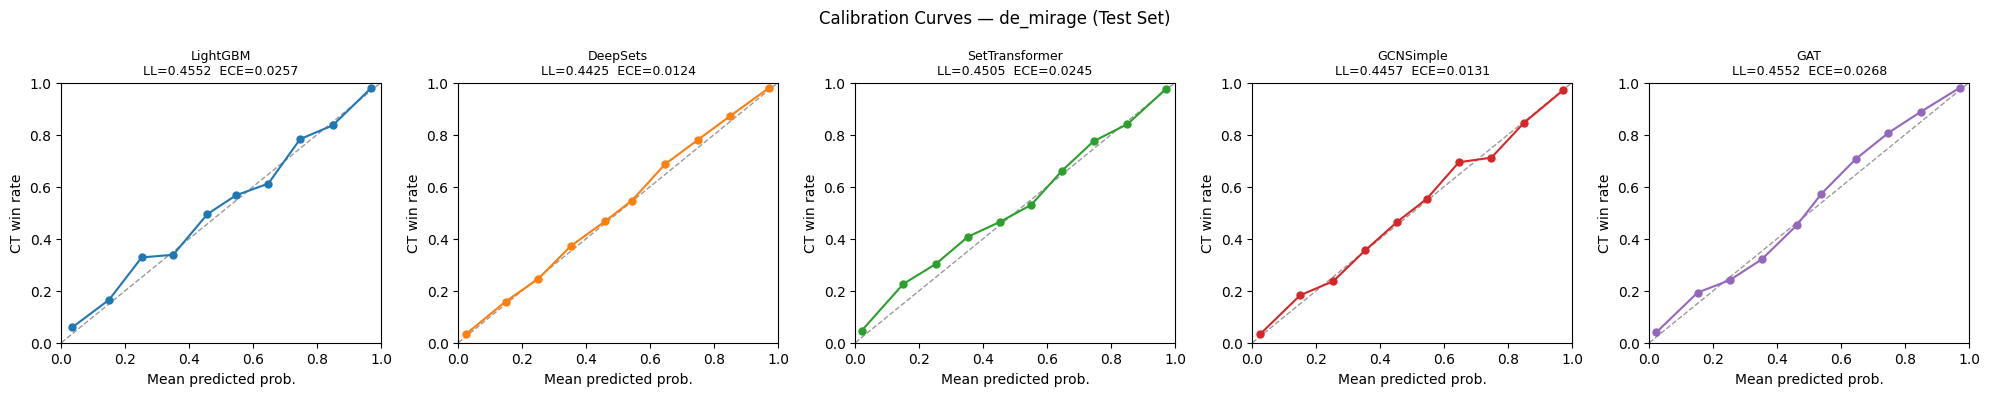

In [23]:
COLORS = dict(zip(MODEL_ORDER, plt.cm.tab10.colors))

def calibration_curve(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    mp, mt = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() > 0:
            mp.append(y_prob[mask].mean())
            mt.append(y_true[mask].mean())
    return np.array(mp), np.array(mt)

fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(4 * len(MODEL_ORDER), 4))
for ax, name in zip(axes, MODEL_ORDER):
    if name not in test_preds: ax.set_visible(False); continue
    yt, yp = test_preds[name]
    mp, mt = calibration_curve(yt, yp)
    ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.4, label='Perfect')
    ax.plot(mp, mt, 'o-', color=COLORS[name], ms=5)
    ax.set_title(f'{name}\nLL={log_loss(yt,yp):.4f}  ECE={compute_ece(yt,yp):.4f}', fontsize=9)
    ax.set_xlabel('Mean predicted prob.'); ax.set_ylabel('CT win rate')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)

plt.suptitle(f'Calibration Curves — de_{MAP_NAME} (Test Set)', fontsize=12)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_calibration.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.3 Time-binned log loss  *(replicates ESTA Fig. 6)*

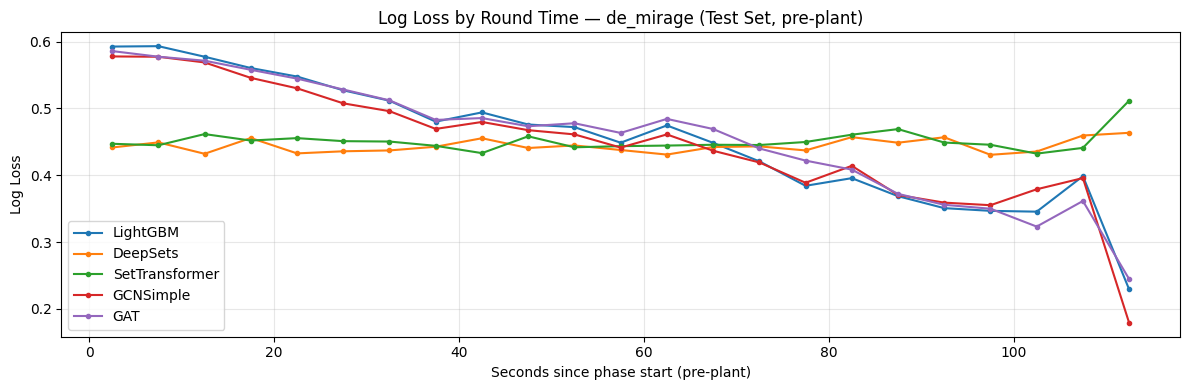

In [24]:
BIN_WIDTH = 5
MAX_TIME  = 115
bin_edges   = np.arange(0, MAX_TIME + BIN_WIDTH, BIN_WIDTH)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
pre_plant_mask = (bomb_arr == 0)

fig, ax = plt.subplots(figsize=(12, 4))
for name in MODEL_ORDER:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    if len(yt) != len(time_arr):
        print(f'  Skipping {name} (length mismatch)'); continue
    ll_bins = []
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        mask = pre_plant_mask & (time_arr >= lo) & (time_arr < hi)
        ll_bins.append(log_loss(yt[mask], yp[mask]) if mask.sum() >= 10 else np.nan)
    ax.plot(bin_centers, ll_bins, '-o', ms=3, lw=1.5, color=COLORS[name], label=name)

ax.set_xlabel('Seconds since phase start (pre-plant)')
ax.set_ylabel('Log Loss')
ax.set_title(f'Log Loss by Round Time — de_{MAP_NAME} (Test Set, pre-plant)')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_ll_by_time.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.4 Late-round log loss  *(full / last-30s pre-plant / post-plant)*

Late pre-plant states (>=85s): 5,602
Post-plant states:                          10,902

Model              Full LL   Late pre-plant LL   Post-plant LL
--------------------------------------------------------------
LightGBM            0.4552              0.3515          0.2587
DeepSets            0.4425              0.4471          0.4438
SetTransformer      0.4505              0.4551          0.4560
GCNSimple           0.4457              0.3576          0.2491
GAT                 0.4552              0.3500          0.2451


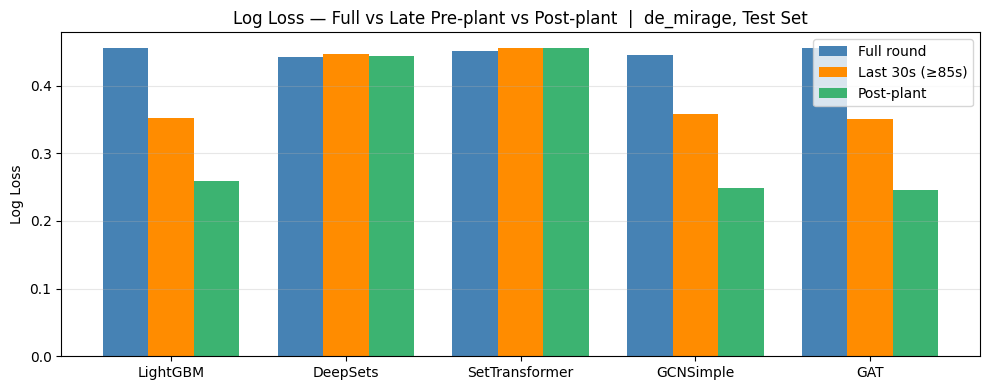

In [25]:
LATE_THRESHOLD = 85   # seconds — last 30s of the 115s round
late_mask  = pre_plant_mask & (time_arr >= LATE_THRESHOLD)
plant_mask = (bomb_arr == 1)

print(f'Late pre-plant states (>={LATE_THRESHOLD}s): {late_mask.sum():,}')
print(f'Post-plant states:                          {plant_mask.sum():,}')
print()

late_results = {}
print(f'{"Model":<16}  {"Full LL":>8}  {"Late pre-plant LL":>18}  {"Post-plant LL":>14}')
print('-' * 62)
for name in MODEL_ORDER:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    if len(yt) != len(time_arr): continue
    ll_f = log_loss(yt, yp)
    ll_l = log_loss(yt[late_mask],  yp[late_mask])  if late_mask.sum()  >= 10 else float('nan')
    ll_p = log_loss(yt[plant_mask], yp[plant_mask]) if plant_mask.sum() >= 10 else float('nan')
    late_results[name] = dict(full=ll_f, late=ll_l, plant=ll_p)
    print(f'{name:<16}  {ll_f:>8.4f}  {ll_l:>18.4f}  {ll_p:>14.4f}')

# Bar chart
names_with_data = [n for n in MODEL_ORDER if n in late_results]
x = np.arange(len(names_with_data)); w = 0.26
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w, [late_results[n]['full']  for n in names_with_data], w, label='Full round',          color='steelblue')
ax.bar(x,     [late_results[n]['late']  for n in names_with_data], w, label=f'Last 30s (≥{LATE_THRESHOLD}s)', color='darkorange')
ax.bar(x + w, [late_results[n]['plant'] for n in names_with_data], w, label='Post-plant',           color='mediumseagreen')
ax.set_xticks(x); ax.set_xticklabels(names_with_data)
ax.set_ylabel('Log Loss')
ax.set_title(f'Log Loss — Full vs Late Pre-plant vs Post-plant  |  de_{MAP_NAME}, Test Set')
ax.legend(); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_ll_late_round.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.5 Round win probability trace  *(qualitative case study)*

Match: StarLadder Major Playoffs_furia-vs-natus-vincere-m1-mirage
Round: 5  |  Outcome: CT wins
States: 138  |  Bomb planted in this round: False


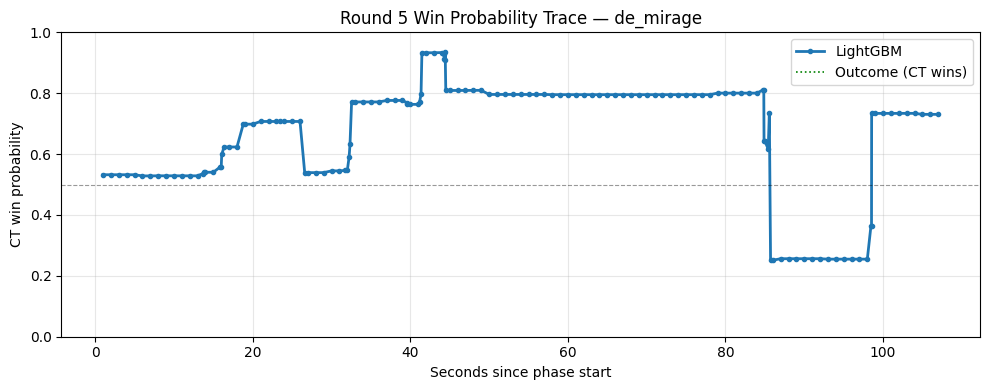

In [26]:
# ── Pick a single round from the test set and plot all models' predictions ─
# Change MATCH_KEY and ROUND_NUM to select a different round.
#
# How to find a good round:
#   - Look for a round where GCNSimple/GAT diverge from LightGBM post-plant
#   - bomb_arr mask tells you which game states are post-plant

MATCH_KEY  = list(test_data.keys())[0]   # change to a specific match key
ROUND_NUM  = 5                            # change to a specific round number

match = test_data[MATCH_KEY]
round_states = [(df_row, label)
                for df_row, label in zip(match['df'], match['Y'])
                if df_row.get('roundNum') == ROUND_NUM]

if not round_states:
    print(f'Round {ROUND_NUM} not found in match {MATCH_KEY}')
else:
    times  = [float(s[0].get('secondsSincePhaseStart', 0)) for s in round_states]
    bombs  = [int(s[0].get('bombPlanted', 0)) for s in round_states]
    y_true = round_states[0][1]  # round outcome (same for all states)

    # Run inference on just this round's states
    # LightGBM — uses vector representation
    X_round = pd.DataFrame([s[0] for s in round_states])
    # Drop non-feature columns (same as training)
    drop_cols = [c for c in ['tick', 'roundNum', 'ctWin'] if c in X_round.columns]
    X_round = X_round.drop(columns=drop_cols).fillna(0)
    lgbm_probs = lgbm_model.predict(X_round)

    # Set / graph models — need to build tensors from GNN/set data
    # (quick approach: filter datasets to this round's indices)
    # This is approximate — for a proper per-round trace use
    # the round visualisation notebook (TODO Chapter 4 figure)
    print(f'Match: {MATCH_KEY}')
    print(f'Round: {ROUND_NUM}  |  Outcome: {"CT wins" if y_true == 1 else "T wins"}')
    print(f'States: {len(round_states)}  |  Bomb planted in this round: {any(bombs)}')

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(times, lgbm_probs, '-o', ms=3, lw=2, color=COLORS['LightGBM'], label='LightGBM')
    ax.axhline(0.5, color='k', lw=0.8, ls='--', alpha=0.4)
    ax.axhline(y_true, color='green' if y_true == 1 else 'red', lw=1.2,
               ls=':', label=f'Outcome ({"CT wins" if y_true==1 else "T wins"})')

    # Mark bomb plant
    plant_idx = next((i for i, b in enumerate(bombs) if b == 1), None)
    if plant_idx is not None:
        ax.axvline(times[plant_idx], color='orange', lw=1.5, ls='--', label='Bomb planted')

    ax.set_xlabel('Seconds since phase start'); ax.set_ylabel('CT win probability')
    ax.set_title(f'Round {ROUND_NUM} Win Probability Trace — de_{MAP_NAME}')
    ax.set_ylim(0, 1); ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(CHECKPOINT_DIR / f'fig_round_trace_r{ROUND_NUM}.png', dpi=150, bbox_inches='tight')
    plt.show()

    # TODO: extend to include GCNSimple and GAT predictions using per-round
    # graph data — this requires extracting the matching GNN states from
    # datasets['graph']['test'] by round index. See Chapter 4 visualisation
    # notebook (separate file) for the full multi-model round trace figure.


## 9. Temporal GNN  *(run in a separate session)*

The TemporalGNN is RAM-heavy (max_seq_len=80, GRU unrolled over full rounds).
Running it alongside the other models causes OOM on Colab free tier.

**Instructions:**
1. Make sure Section 0–3 are already run and data is loaded.
2. Skip Sections 5.1–5.5 and jump directly here.
3. After training, run Section 7–8 as normal — `TemporalGNN` will be
   added to `test_preds` and will appear in all plots.

Known issues on de_dust2:
- Erratic val LL (swings ±0.3 between epochs). Partially mitigated by
  `lr=3e-4` and `grad_clip=0.5`. Does not fully converge.
- Best val LL 0.6265 (epoch 6), test LL 0.6342.
- Per-step qualitative behaviour is correct (LL decreases over round time).

In [ ]:
from torch.utils.data import DataLoader as TorchDataLoader

# ── Build temporal datasets ───────────────────────────────────────────────
temporal_train = TemporalGraphDataset(train_data, max_len=CFG['max_seq_len'])
temporal_val   = TemporalGraphDataset(val_data,   max_len=CFG['max_seq_len'])
temporal_test  = TemporalGraphDataset(test_data,  max_len=CFG['max_seq_len'])
print(f'Temporal datasets: train={len(temporal_train)} val={len(temporal_val)} test={len(temporal_test)} rounds')


In [ ]:
# ── Train TemporalGNN ─────────────────────────────────────────────────────
# Uses lower lr and tighter grad_clip than other models — critical for stability
tgnn_ckpt = CHECKPOINT_DIR / 'temporal_gnn.pt'

temporal_model = TemporalGNN(hidden=128).to(DEVICE)

if tgnn_ckpt.exists():
    print('  Checkpoint found → loading')
    temporal_model.load_state_dict(torch.load(tgnn_ckpt, map_location=DEVICE))
    temporal_model.eval()
else:
    optim = Adam(temporal_model.parameters(),
                 lr=CFG['lr_temporal'], weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    train_loader = TorchDataLoader(temporal_train, batch_size=CFG['batch_size'],
                                   shuffle=True, collate_fn=temporal_collate_fn)
    val_loader   = TorchDataLoader(temporal_val,   batch_size=CFG['batch_size'],
                                   shuffle=False, collate_fn=temporal_collate_fn)
    best_val, best_ep, no_improve = float('inf'), 0, 0

    for ep in range(1, CFG['epochs'] + 1):
        temporal_model.train()
        tot_loss, tot_n = 0.0, 0
        for ts_batches, masks, labels in train_loader:
            lbl = labels.float().unsqueeze(1).to(DEVICE)
            optim.zero_grad()
            loss = crit(temporal_model(ts_batches, masks, lbl.size(0)), lbl)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(temporal_model.parameters(), CFG['grad_clip_temporal'])
            optim.step()
            tot_loss += loss.item() * lbl.size(0); tot_n += lbl.size(0)

        temporal_model.eval()
        val_probs, val_trues = [], []
        with torch.no_grad():
            for ts_batches, masks, labels in val_loader:
                lbl = labels.float().unsqueeze(1).to(DEVICE)
                logits = temporal_model(ts_batches, masks, lbl.size(0))
                val_probs.append(torch.sigmoid(logits).cpu().numpy().flatten())
                val_trues.append(labels.numpy().flatten())
        val_ll = log_loss(np.concatenate(val_trues), np.concatenate(val_probs))
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')

        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(temporal_model.state_dict(), tgnn_ckpt)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break

    temporal_model.load_state_dict(torch.load(tgnn_ckpt, map_location=DEVICE))
    temporal_model.eval()


In [ ]:
# ── Evaluate TemporalGNN on test set and add to test_preds ───────────────
test_loader = TorchDataLoader(temporal_test, batch_size=CFG['batch_size'],
                               shuffle=False, collate_fn=temporal_collate_fn)
tgnn_probs, tgnn_trues = [], []
with torch.no_grad():
    for ts_batches, masks, labels in test_loader:
        lbl = labels.float().unsqueeze(1).to(DEVICE)
        logits = temporal_model(ts_batches, masks, lbl.size(0))
        tgnn_probs.append(torch.sigmoid(logits).cpu().numpy().flatten())
        tgnn_trues.append(labels.numpy().flatten())

tgnn_y, tgnn_p = np.concatenate(tgnn_trues), np.concatenate(tgnn_probs)
evaluate_numpy(tgnn_y, tgnn_p, 'TemporalGNN/test')

# Note: TemporalGNN produces one prediction per ROUND, not per game state,
# so it cannot be directly aligned with time_arr for the time-binned plots.
# Use the per-step inference helper in the dust2 notebook (cells 53-56)
# if you need time-binned TemporalGNN results.
test_preds['TemporalGNN'] = (tgnn_y, tgnn_p)
print('TemporalGNN added to test_preds.')
